# LM4 Lab — Optimization in One Variable

Companion notebook to **From Calculus to Kelly, LM4**. It rebuilds every computational exhibit and example of the module and solves the computational practice problems. Each part ends with checks against the numbers printed in the module.

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token (set `FINMIND_TOKEN`). From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

| Part | Rebuilds |
|:--|:--|
| 1 | Total-return series for 0050 (dividends, split, common trading days) |
| 2 | The empirical growth function: Exhibit 1, Exhibit 3, Example 1 (and why the quadratic rule overshoots), Example 2 |
| 3 | Corners: Exhibit 4 (with the partial years it leaves out) and Example 3 |
| 4 | The binary Kelly bet: Example 4, Exhibit 5 and the relative-entropy identity |
| 5 | Root finding: Exhibit 6, the degree of the cleared Kelly condition, Example 5, the two-IRR pitfall |
| 6 | Sensitivity: Exhibit 7, Example 6, Example 7, Example 8, Exhibit 8, the Sharpe-3 pitfall |
| 7 | `scipy.optimize`, including the unbounded-search failure of the last Knowledge Check |
| 8 | Practice-problem solutions and an extension exercise |

**Notation (as in the module).** $f$ is the leverage, $f^*$ its growth-optimal (Kelly) value and $c=f/f^*$ the fraction of full Kelly. A binary bet gains $b$ or loses $a$ per unit staked, with win probability $p$ and $q=1-p$.

**Files.** `data/` then holds FinMind `TaiwanStockPrice` closes for 0050 and 00631L (2014-10-31 → 2026-10-08, unadjusted, with FinMind's `spread` column) and 0050 cash dividends from `TaiwanStockDividendResult`: the windows the book retrieved on 2026-10-10, which `fetch_finmind.py` checks against `data/raw_manifest.json`. 00631L is needed only to reproduce the common trading days used throughout the book. The code runs on Polars 1.x and later versions.

In [1]:
from pathlib import Path
import math
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from scipy.optimize import brentq, minimize_scalar, newton

DATA = Path("data")
pl.Config.set_tbl_rows(30)
pl.Config.set_float_precision(6)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

def check(value, expected, ndigits, label):
    # module numbers are printed at a given precision; reproduce them exactly at that precision
    ok = round(value, ndigits) == round(expected, ndigits)
    print(f"{'ok ' if ok else 'XX '} {label}: {value:.{ndigits + 2}f} (module: {expected})")
    assert ok, label

## Part 1 — Total returns on common trading days

As in LM3, the total return is $R_t=(P_t+D_t)/P_{t-1}-1$ with the cash dividend $D_t$ on ex-dates; on a split day the previous close is first restated per new share (0050 4-for-1 on 2025-06-18; 00631L 22-for-1 on 2026-03-31), which the code does with the split factor `k`. Returns are computed between consecutive trading days common to both funds, so that every module in the book uses the same 2,902 observations. First, every close is checked against FinMind's own `spread` column.

In [2]:
SPLITS = {"0050": ("2025-06-18", 4), "00631L": ("2026-03-31", 22)}
div = pl.read_csv(DATA / "0050_dividends.csv")

def load_raw(sym):
    df = pl.read_csv(DATA / f"{sym}_daily_raw.csv").sort("date")
    gap = (pl.col("close") - pl.col("close").shift(1) - pl.col("spread")).abs()
    bad = df.with_columns(gap.alias("gap")).filter(pl.col("gap") > 0.005)
    expected = (set(div["date"]) if sym == "0050" else set()) | {SPLITS[sym][0]}
    unexplained = set(bad["date"]) - expected
    print(f"{sym}: {df.height} rows, spread mismatches {bad.height}, unexplained {sorted(unexplained)}")
    assert not unexplained
    return df

def with_actions(sym):
    df = load_raw(sym)
    sd, k = SPLITS[sym]
    d = (div.select("date", pl.col("cash_dividend").alias("D")) if sym == "0050"
         else pl.DataFrame({"date": [], "D": []}, schema={"date": pl.Utf8, "D": pl.Float64}))
    return (df.join(d, on="date", how="left")
              .with_columns(pl.col("D").fill_null(0.0),
                            pl.when(pl.col("date") == pl.lit(sd)).then(pl.lit(float(k))).otherwise(pl.lit(1.0)).alias("k"))
              .select("date", pl.col("close").alias(f"P_{sym}"), pl.col("D").alias(f"D_{sym}"), pl.col("k").alias(f"k_{sym}")))

both = with_actions("0050").join(with_actions("00631L"), on="date", how="inner").sort("date")
ret = (both.with_columns(
           ((pl.col("P_0050") + pl.col("D_0050")) / (pl.col("P_0050").shift(1) / pl.col("k_0050")) - 1).alias("R"))
           .drop_nulls("R")
           .with_columns(pl.col("date").str.to_date())
           .select("date", "R"))
R = ret["R"].to_numpy()
T = len(R)
YEARS = (ret["date"][-1] - pl.Series(["2014-10-31"]).str.to_date()[0]).days / 365.25   # base close 2014-10-31
A = T / YEARS                                                                            # trading days a year
print(f"T = {T}, {ret['date'][0]} -> {ret['date'][-1]}, {YEARS:.3f} years, A = {A:.2f} trading days a year")
print(f"worst day {ret['date'][int(R.argmin())]}: {R.min():.4%};  best day {ret['date'][int(R.argmax())]}: {R.max():.4%}")
check(T, 2902, 0, "number of returns")
check(YEARS, 11.937, 3, "years from 31 October 2014 to 8 October 2026")
check(A, 243.11, 2, "trading days a year, A")

0050: 2907 rows, spread mismatches 23, unexplained []
00631L: 2908 rows, spread mismatches 1, unexplained []
T = 2902, 2014-11-03 -> 2026-10-08, 11.937 years, A = 243.11 trading days a year
worst day 2025-04-07: -10.0000%;  best day 2026-07-31: 10.0000%
ok  number of returns: 2902.00 (module: 2902)
ok  years from 31 October 2014 to 8 October 2026: 11.93703 (module: 11.937)
ok  trading days a year, A: 243.1091 (module: 243.11)


## Part 2 — The empirical growth function (Sections 2 and 3)

$\bar g(f)=\frac1T\sum_t\ln(1+fR_t)$ (4.4), $\bar g'(f)=\frac1T\sum_t R_t/(1+fR_t)$ (4.5), $\bar g''(f)=-\frac1T\sum_t R_t^2/(1+fR_t)^2$ (4.6), on the domain $(-1/R_{\max},\,1/\lvert R_{\min}\rvert)$.

In [3]:
def gbar(f, r=R):  return float(np.log1p(f * r).mean())
def dg(f, r=R):    return float((r / (1 + f * r)).mean())
def d2g(f, r=R):   return float(-((r / (1 + f * r)) ** 2).mean())

def domain(r):
    return -1 / r.max(), 1 / -r.min()

def kelly(r, xtol=1e-15):
    lo, hi = domain(r)
    return brentq(lambda f: dg(f, r), lo * (1 - 1e-12), hi * (1 - 1e-12), xtol=xtol)

lo, hi = domain(R)
mu, s2 = R.mean(), R.var()                    # population variance
m2 = (R**2).mean()
f_star = kelly(R)
g_star = gbar(f_star)
f_zero = brentq(gbar, f_star, hi * (1 - 1e-12), xtol=1e-14)
print(f"domain ({lo:.4f}, {hi:.4f});  mu = {mu:.5%}, s = {math.sqrt(s2):.4%}, m2 = {m2:.4e}")
print(f"f* = {f_star:.6f};  g* = {g_star * A:.4%} a year;  zero growth at {f_zero:.4f} = {f_zero / f_star:.3f} f*")
check(f_star, 5.42, 2, "full Kelly f*"); check(g_star * A, 0.5884, 4, "annual growth at f*")
check(f_zero, 9.74, 2, "zero-growth leverage"); check(mu / s2, 5.68, 2, "mu/s^2"); check(mu / m2, 5.652, 3, "mu/(s^2+mu^2)")
check(mu, 0.0008712, 7, "mean daily return"); check(math.sqrt(s2), 0.012385, 6, "population standard deviation")
check(0.0008712 / 0.012385**2, 5.68, 2, "mu/s^2 from the printed mu and s")

domain (-10.0000, 10.0000);  mu = 0.08712%, s = 1.2385%, m2 = 1.5415e-04
f* = 5.421488;  g* = 58.8363% a year;  zero growth at 9.7365 = 1.796 f*
ok  full Kelly f*: 5.4215 (module: 5.42)
ok  annual growth at f*: 0.588363 (module: 0.5884)
ok  zero-growth leverage: 9.7365 (module: 9.74)
ok  mu/s^2: 5.6796 (module: 5.68)
ok  mu/(s^2+mu^2): 5.65164 (module: 5.652)
ok  mean daily return: 0.000871205 (module: 0.0008712)
ok  population standard deviation: 0.01238514 (module: 0.012385)
ok  mu/s^2 from the printed mu and s: 5.6797 (module: 5.68)


In [4]:
def max_drawdown(f, r=R):
    w = np.concatenate([[1.0], np.cumprod(1 + f * r)])
    return float((w / np.maximum.accumulate(w) - 1).min())

levels = [("1 (0050 itself)", 1.0), ("2 (exact daily 2x)", 2.0), ("half Kelly", f_star / 2), ("full Kelly", f_star), ("zero growth", f_zero)]
case = pl.DataFrame({
    "leverage": [n for n, _ in levels],
    "f": [f for _, f in levels],
    "annual log growth": [gbar(f) * A for _, f in levels],
    "growth of 1 unit": [math.exp(gbar(f) * T) for _, f in levels],
    "annualized vol": [f * math.sqrt(s2 * A) for _, f in levels],
    "max drawdown": [max_drawdown(f) for _, f in levels],
    "worst day": [f * R.min() for _, f in levels],
})
case   # Exhibit 1

leverage,f,annual log growth,growth of 1 unit,annualized vol,max drawdown,worst day
str,f64,f64,f64,f64,f64,f64
"""1 (0050 itself)""",1.000000,0.193082,10.022465,0.193109,-0.339292,-0.100000
"""2 (exact daily 2x)""",2.000000,0.348694,64.223268,0.386217,-0.579160,-0.200000
"""half Kelly""",2.710744,0.436329,182.813806,0.523468,-0.701425,-0.271074
"""full Kelly""",5.421488,0.588363,1122.490157,1.046936,-0.932592,-0.542149
"""zero growth""",9.736503,0.000000,1.000000,1.880202,-0.999916,-0.973650


In [5]:
check(case["growth of 1 unit"][3], 1122.5, 1, "growth of 1 unit at f*")
check(case["max drawdown"][3], -0.933, 3, "max drawdown at f*")
for i, vol in enumerate((0.193, 0.386, 0.523, 1.047, 1.880)):
    check(case["annualized vol"][i], vol, 3, f"annualized volatility, row {i + 1}")
# the note's recipe f s sqrt(A) with the printed s and A: rows 3-5 need the unrounded leverages it names
for f_row, vol in ((2.7107, 0.523), (5.4215, 1.047), (9.7365, 1.880)):
    check(f_row * 0.012385 * math.sqrt(243.11), vol, 3, f"volatility of f = {f_row} from the printed recipe")
check(case["annual log growth"][2] / case["annual log growth"][3], 0.742, 3, "half-Kelly share of growth")
check(case["max drawdown"][2], -0.701, 3, "max drawdown at half Kelly")

# Example 1 (1): the quadratic rule, and volatility drag at the optimum
print(f"quadratic growth at mu/m2: {mu**2 / (2 * m2) * A:.2%} a year;  rule {mu / m2 / f_star - 1:.1%} above the exact f*")
print(f"levered arithmetic mean at f*: {f_star * mu * A:.2%} a year, of which log growth keeps {g_star / (f_star * mu):.1%}")
check(mu**2 / (2 * m2) * A, 0.5985, 4, "quadratic model's maximal growth")
check(g_star / (f_star * mu), 0.51, 2, "share of the levered mean kept at f*")

ok  growth of 1 unit at f*: 1122.490 (module: 1122.5)
ok  max drawdown at f*: -0.93259 (module: -0.933)
ok  annualized volatility, row 1: 0.19311 (module: 0.193)
ok  annualized volatility, row 2: 0.38622 (module: 0.386)
ok  annualized volatility, row 3: 0.52347 (module: 0.523)
ok  annualized volatility, row 4: 1.04694 (module: 1.047)
ok  annualized volatility, row 5: 1.88020 (module: 1.88)
ok  volatility of f = 2.7107 from the printed recipe: 0.52345 (module: 0.523)
ok  volatility of f = 5.4215 from the printed recipe: 1.04693 (module: 1.047)
ok  volatility of f = 9.7365 from the printed recipe: 1.88018 (module: 1.88)
ok  half-Kelly share of growth: 0.74160 (module: 0.742)
ok  max drawdown at half Kelly: -0.70143 (module: -0.701)
quadratic growth at mu/m2: 59.85% a year;  rule 4.2% above the exact f*
levered arithmetic mean at f*: 114.83% a year, of which log growth keeps 51.2%
ok  quadratic model's maximal growth: 0.598503 (module: 0.5985)
ok  share of the levered mean kept at f*: 0.5

In [6]:
# Example 1 (1): why the rule overshoots. Two more terms of ln(1+x) add f^2 m3 - f^3 m4 to the first-order
# condition. For normal returns with the same mean and s they cancel at f = mu/s^2; 0050's fourth moment is far larger.
m3, m4 = (R**3).mean(), (R**4).mean()
fq = mu / m2
m3N = mu**3 + 3 * mu * s2                                    # normal returns with 0050's mu and s
m4N = mu**4 + 6 * mu**2 * s2 + 3 * s2**2
exkurt = ((R - mu) ** 4).mean() / s2**2 - 3
print(f"at f_q = {fq:.4f}:  0050  f^2 m3 = {fq**2 * m3:.3e}, f^3 m4 = {fq**3 * m4:.3e}")
print(f"               normal f^2 m3 = {fq**2 * m3N:.3e}, f^3 m4 = {fq**3 * m4N:.3e}")
print(f"excess kurtosis {exkurt:.2f};  m4 is {m4 / m4N:.2f} times the normal value")
limit = np.abs(R) >= 0.0999                                  # the two limit days: 2025-04-07 (-10%), 2026-07-31 (+10%)
Rx = R[~limit]
print(f"without {ret['date'].filter(pl.Series(limit)).to_list()}: rule mu/m2 = {Rx.mean() / (Rx**2).mean():.4f}, exact {kelly(Rx):.4f}, "
      f"excess kurtosis {((Rx - Rx.mean()) ** 4).mean() / Rx.var() ** 2 - 3:.2f}")
check(exkurt, 8.12, 2, "excess kurtosis")
check(m4 / m4N, 3.7, 1, "m4 relative to normal returns")
check(Rx.mean() / (Rx**2).mean(), 5.92, 2, "rule without the two limit days")
check(kelly(Rx), 5.74, 2, "exact optimum without the two limit days")
gap, gap_x = mu / m2 - f_star, Rx.mean() / (Rx**2).mean() - kelly(Rx)
print(f"overshoot of the rule: {gap:.4f} on the full sample, {gap_x:.4f} without the two days ({gap_x / gap:.0%} of it)")
check(gap_x / gap, 0.75, 2, "share of the overshoot left without the two limit days (three-quarters)")

# Example 2: the worst day at the zero-growth leverage
print(f"worst day at f0: 1 - {f_zero * 0.1:.4f} = {1 - f_zero * 0.1:.4f}, log {math.log1p(f_zero * R.min()):.2f};  "
      f"at f*: {math.log1p(f_star * R.min()):.2f} of total {g_star * T:.2f}")
check(f_zero, 9.737, 3, "zero-growth leverage to three decimals")
check(1 - f_zero * 0.1, 0.0263, 4, "equity left after the worst day at f0")
check(math.log1p(f_zero * R.min()), -3.64, 2, "worst-day log return at f0")
check(2 * mu / m2, 11.30, 2, "quadratic model's zero")

at f_q = 5.6516:  0050  f^2 m3 = 1.505e-05, f^3 m4 = 4.740e-05
               normal f^2 m3 = 1.283e-05, f^3 m4 = 1.287e-05
excess kurtosis 8.12;  m4 is 3.68 times the normal value
without [datetime.date(2025, 4, 7), datetime.date(2026, 7, 31)]: rule mu/m2 = 5.9161, exact 5.7442, excess kurtosis 5.97
ok  excess kurtosis: 8.1205 (module: 8.12)
ok  m4 relative to normal returns: 3.684 (module: 3.7)
ok  rule without the two limit days: 5.9161 (module: 5.92)
ok  exact optimum without the two limit days: 5.7442 (module: 5.74)
overshoot of the rule: 0.2302 on the full sample, 0.1719 without the two days (75% of it)
ok  share of the overshoot left without the two limit days (three-quarters): 0.7469 (module: 0.75)
worst day at f0: 1 - 0.9737 = 0.0263, log -3.64;  at f*: -0.78 of total 7.02
ok  zero-growth leverage to three decimals: 9.73650 (module: 9.737)
ok  equity left after the worst day at f0: 0.026350 (module: 0.0263)
ok  worst-day log return at f0: -3.6363 (module: -3.64)
ok  quadratic 

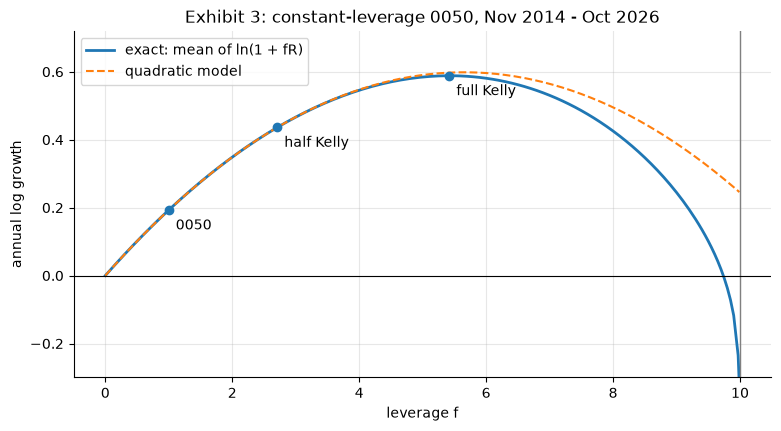

In [7]:
fs_grid = np.concatenate([np.arange(0, 9.95, 0.05), [9.97, 9.99]])
fig, ax = plt.subplots()
ax.plot(fs_grid, [gbar(f) * A for f in fs_grid], lw=2, label="exact: mean of ln(1 + fR)")
ax.plot(fs_grid, (fs_grid * mu - fs_grid**2 * m2 / 2) * A, "--", label="quadratic model")
for f, lab in [(1, "0050"), (f_star / 2, "half Kelly"), (f_star, "full Kelly")]:
    ax.plot(f, gbar(f) * A, "o", color="C0"); ax.annotate(lab, (f, gbar(f) * A), xytext=(5, -14), textcoords="offset points")
ax.axvline(10, color="grey", lw=1); ax.axhline(0, color="black", lw=0.8)
ax.set_ylim(-0.3, 0.72); ax.set_xlabel("leverage f"); ax.set_ylabel("annual log growth")
ax.set_title("Exhibit 3: constant-leverage 0050, Nov 2014 - Oct 2026"); ax.legend(); plt.show()

## Part 3 — Corners (Section 4)

For a concave objective the optimum on $[\alpha,\beta]$ is the unconstrained optimum clipped to the interval. Exhibit 4 computes the empirical Kelly leverage in each full calendar year, each on its own domain; the partial years 2014 and 2026 enter only the full-sample row.

In [8]:
def year_row(y):
    r = ret.filter(pl.col("date").dt.year() == y)["R"].to_numpy()
    fy = kelly(r)
    return {"year": y, "returns": len(r), "total return": float(np.prod(1 + r) - 1), "mu (bp/day)": r.mean() * 1e4,
            "s (%/day)": r.std() * 100, "f* unconstrained": fy, "optimum on [0,2]": min(max(fy, 0.0), 2.0)}

years = pl.DataFrame([year_row(y) for y in range(2015, 2026)])
partial = pl.DataFrame([year_row(y) for y in (2014, 2026)])
print("partial years, left out of the rows:"); print(partial)
years   # Exhibit 4

partial years, left out of the rows:
shape: (2, 7)
┌──────┬─────────┬──────────────┬─────────────┬───────────┬──────────────────┬──────────────────┐
│ year ┆ returns ┆ total return ┆ mu (bp/day) ┆ s (%/day) ┆ f* unconstrained ┆ optimum on [0,2] │
│ ---  ┆ ---     ┆ ---          ┆ ---         ┆ ---       ┆ ---              ┆ ---              │
│ i64  ┆ i64     ┆ f64          ┆ f64         ┆ f64       ┆ f64              ┆ f64              │
╞══════╪═════════╪══════════════╪═════════════╪═══════════╪══════════════════╪══════════════════╡
│ 2014 ┆ 44      ┆ 0.023737     ┆ 5.695600    ┆ 0.852455  ┆ 7.967772         ┆ 2.000000         │
│ 2026 ┆ 181     ┆ 0.787092     ┆ 34.057972   ┆ 1.974314  ┆ 8.802979         ┆ 2.000000         │
└──────┴─────────┴──────────────┴─────────────┴───────────┴──────────────────┴──────────────────┘


year,returns,total return,mu (bp/day),s (%/day),f* unconstrained,"optimum on [0,2]"
i64,i64,f64,f64,f64,f64,f64
2015,244,-0.063093,-2.126724,1.044064,-1.933218,0.000000
2016,244,0.196442,7.809605,0.955539,8.370955,2.000000
2017,246,0.181338,6.951971,0.592457,19.410056,2.000000
2018,247,-0.049511,-1.502588,1.046024,-1.399963,0.000000
2019,242,0.335157,12.256514,0.782030,19.732696,2.000000
2020,245,0.310844,12.123043,1.462384,5.436369,2.000000
2021,244,0.219709,8.775000,1.125741,6.966230,2.000000
2022,246,-0.213416,-8.790322,1.388528,-4.459940,0.000000
2023,239,0.273978,10.534856,0.894305,13.582159,2.000000


In [9]:
check(years["f* unconstrained"].min(), -4.46, 2, "lowest yearly f* (2022)")
check(years["f* unconstrained"].max(), 19.73, 2, "highest yearly f* (2019)")
assert set(years["optimum on [0,2]"].to_list()) == {0.0, 2.0}            # every constrained optimum is a corner
assert years.filter(pl.col("mu (bp/day)") < 0)["optimum on [0,2]"].to_list() == [0.0, 0.0, 0.0]
check(partial["total return"][0], 0.0237, 4, "2014 (from 3 November)"); check(partial["f* unconstrained"][0], 7.97, 2, "2014 f*")
check(partial["total return"][1], 0.7871, 4, "2026 (to 8 October)"); check(partial["f* unconstrained"][1], 8.80, 2, "2026 f*")
check(float(np.prod(1 + years["total return"].to_numpy()) - 1), 4.478, 3, "full years 2015-2025 compounded")
check(float(np.prod(1 + R) - 1), 9.0225, 4, "whole sample")

# Example 3: the 2x ceiling and its shadow price
print(f"g(2) = {gbar(2) * A:.2%} a year, x{math.exp(gbar(2) * T):.1f};  shadow price g'(2) = {dg(2) * A:.2%} a year per unit")
print(f"raise the cap to 2.5: first-order {0.5 * dg(2) * A:.2%}, exact {(gbar(2.5) - gbar(2)) * A:.2%}")
check(dg(2) * A, 0.1368, 4, "shadow price of the 2x cap")
check((gbar(2.5) - gbar(2)) * A, 0.0637, 4, "exact gain from 2 to 2.5")

ok  lowest yearly f* (2022): -4.4599 (module: -4.46)
ok  highest yearly f* (2019): 19.7327 (module: 19.73)
ok  2014 (from 3 November): 0.023737 (module: 0.0237)
ok  2014 f*: 7.9678 (module: 7.97)
ok  2026 (to 8 October): 0.787092 (module: 0.7871)
ok  2026 f*: 8.8030 (module: 8.8)
ok  full years 2015-2025 compounded: 4.47822 (module: 4.478)
ok  whole sample: 9.022465 (module: 9.0225)
g(2) = 34.87% a year, x64.2;  shadow price g'(2) = 13.68% a year per unit
raise the cap to 2.5: first-order 6.84%, exact 6.37%
ok  shadow price of the 2x cap: 0.136789 (module: 0.1368)
ok  exact gain from 2 to 2.5: 0.063656 (module: 0.0637)


## Part 4 — The binary Kelly bet (Section 5)

A bet gains $b$ or loses $a$ per unit staked: $g(f)=p\ln(1+fb)+q\ln(1-fa)$ (4.7), $f^*=p/a-q/b=(1/a+1/b)(p-\pi)$ with $\pi=a/(a+b)$ (4.8, 4.10), and $g^*$ from (4.9).

In [10]:
def g_bin(f, p, b, a):  return p * math.log1p(f * b) + (1 - p) * math.log1p(-f * a)
def f_bin(p, b, a):     return p / a - (1 - p) / b
def g_star_bin(p, b, a):
    q = 1 - p
    return p * math.log(p * (a + b) / a) + q * math.log(q * (a + b) / b)

# Example 4: +2% / -1% at p = 0.5
p, b, a = 0.5, 0.02, 0.01
fb = f_bin(p, b, a); gb = g_star_bin(p, b, a)
print(f"f* = {fb:.2f}, risk {fb * a:.0%} = p - q a/b = {p - (1 - p) * a / b:.2f}, g* = {gb:.4%} per trade (check {g_bin(fb, p, b, a):.6f})")
print(f"0.25x: {g_bin(0.25, p, b, a):.4%} per trade = {g_bin(0.25, p, b, a) / gb:.1%} of g*;  zero growth at "
      f"{brentq(lambda f: g_bin(f, p, b, a), fb, 99.999999):.4f}")
check(gb, 0.05889, 5, "g* of the +2/-1 bet")

# Exhibit 5: the bet as p falls; growth at a fixed 25x
p0 = math.log(1 / 0.75) / math.log(1.5 / 0.75)
rows = []
for pp in (0.60, 0.55, 0.50, 0.45, p0, 0.40, 1 / 3):
    fp = f_bin(pp, b, a)
    rows.append({"p": pp, "f*": fp, "risk f*a": fp * a, "g*": g_star_bin(pp, b, a) if fp > 1e-12 else 0.0, "g at 25x": g_bin(25, pp, b, a)})
print(f"zero growth at fixed 25x: p = {p0:.5f}, where f* = {f_bin(p0, b, a):.2f} and 25/f* = {25 / f_bin(p0, b, a):.2f}")
pl.DataFrame(rows)   # Exhibit 5

f* = 25.00, risk 25% = p - q a/b = 0.25, g* = 5.8892% per trade (check 0.058892)
0.25x: 0.1242% per trade = 2.1% of g*;  zero growth at 50.0000
ok  g* of the +2/-1 bet: 0.0588915 (module: 0.05889)
zero growth at fixed 25x: p = 0.41504, where f* = 12.26 and 25/f* = 2.04


p,f*,risk f*a,g*,g at 25x
f64,f64,f64,f64,f64
0.600000,40.000000,0.400000,0.148342,0.128206
0.550000,32.500000,0.325000,0.098557,0.093549
0.500000,25.000000,0.250000,0.058892,0.058892
0.450000,17.500000,0.175000,0.029243,0.024234
0.415037,12.255625,0.122556,0.014508,-0.000000
0.400000,10.000000,0.100000,0.009712,-0.010423
0.333333,-0.000000,-0.000000,0.000000,-0.056633


In [11]:
# Knowledge Check of Section 5: +3% / -1.5% at p = 0.45
print(f"f* = {f_bin(0.45, 0.03, 0.015):.2f}, risk {f_bin(0.45, 0.03, 0.015) * 0.015:.1%}, p - q a/b = {0.45 - 0.55 * 0.015 / 0.03:.3f}")

# the relative-entropy identity of the Deep Dive: g* = D_KL(p || pi)
p, b, a = 0.5, 0.02, 0.01
pi = a / (a + b)
print(f"D_KL(p||pi) = {p * math.log(p / pi) + (1 - p) * math.log((1 - p) / (1 - pi)):.6f}  vs  g* = {g_star_bin(p, b, a):.6f}")

f* = 11.67, risk 17.5%, p - q a/b = 0.175
D_KL(p||pi) = 0.058892  vs  g* = 0.058892


## Part 5 — Root finding (Section 6)

Bisection halves a sign-change bracket; Newton's method (4.12) jumps to the root of the tangent and squares the error (4.13). The traces below run in double precision, as any reader's code does; Exhibit 6 prints its errors from 50-digit arithmetic on the exact returns, because the last ones are at the level of double-precision rounding. The cell after the table redoes both traces with the standard library's `decimal` module.

In [12]:
def bisection_trace(u, lo, hi, tol):
    out = [(0, lo, hi)]
    n = 0
    while hi - lo >= tol:
        n += 1
        m = (lo + hi) / 2
        lo, hi = (m, hi) if u(m) > 0 else (lo, m)
        out.append((n, lo, hi))
    return out

def newton_trace(u, du, x0, steps):
    xs = [x0]
    for _ in range(steps):
        xs.append(xs[-1] - u(xs[-1]) / du(xs[-1]))
    return xs

nt = newton_trace(dg, d2g, 0.0, 5)
assert dg(0.0) > 0 > dg(9.9)                       # dg(9.9) < 0: dg -> -inf as f -> 10, where it is undefined
bt = bisection_trace(dg, 0.0, 9.9, 1e-12)
picks = [0, 1, 2, 3, 4, 10, 20, 30, len(bt) - 1]
iters = pl.DataFrame({
    "n": picks,
    "Newton f_n": [nt[n] if n <= 4 else None for n in picks],
    "Newton error": [abs(nt[n] - f_star) if n <= 4 else None for n in picks],
    "bisection width": [bt[n][2] - bt[n][1] for n in picks],
    "bisection midpoint error": [abs((bt[n][1] + bt[n][2]) / 2 - f_star) for n in picks],
})
e = [abs(x - f_star) for x in nt]
C = abs(2 * float(((R / (1 + f_star * R)) ** 3).mean()) / (2 * d2g(f_star)))
print("Newton ratios e(n+1)/e(n)^2 for n = 1, 2:", [round(e[k + 1] / e[k] ** 2, 3) for k in (1, 2)], f" C = {C:.3f}")
print("bisection steps to width < 1e-12:", len(bt) - 1)
iters   # Exhibit 6

Newton ratios e(n+1)/e(n)^2 for n = 1, 2: [0.046, 0.043]  C = 0.043
bisection steps to width < 1e-12: 44


n,Newton f_n,Newton error,bisection width,bisection midpoint error
i64,f64,f64,f64,f64
0,0.000000,5.421488,9.900000,0.471488
1,5.651643,0.230155,4.950000,2.003512
2,5.423915,0.002427,2.475000,0.766012
3,5.421488,0.000000,1.237500,0.147262
4,5.421488,0.000000,0.618750,0.162113
10,null,null,0.009668,0.002591
20,null,null,0.000009,0.000000
30,null,null,0.000000,0.000000
44,null,null,0.000000,0.000000


In [13]:
# Exhibit 6 in 50-digit arithmetic. In double precision Newton's step-4 error is a few units in the last place of
# f* (8.9e-16 each), and the double-precision f* is itself off by a few units. Exact returns are rebuilt from the
# 2-decimal closes and dividends of Part 1; f* is solved to full precision; both traces are rerun.
from decimal import Decimal, getcontext
getcontext().prec = 50
P_x = [Decimal(repr(x)) for x in both["P_0050"].to_list()]
D_x = [Decimal(repr(x)) for x in both["D_0050"].to_list()]
k_x = [Decimal(repr(x)) for x in both["k_0050"].to_list()]
RX = [(P_x[i] + D_x[i]) * k_x[i] / P_x[i - 1] - 1 for i in range(1, len(P_x))]
assert len(RX) == T and max(abs(float(x) - y) for x, y in zip(RX, R.tolist())) < 1e-15

def dg_x(f):  return sum(r / (1 + f * r) for r in RX) / len(RX)
def d2g_x(f): return -sum((r / (1 + f * r)) ** 2 for r in RX) / len(RX)

f_x = Decimal(0)
for _ in range(10):                                  # quadratic convergence: ten steps from 0 exhaust 50 digits
    f_x -= dg_x(f_x) / d2g_x(f_x)
newton_x = [Decimal(0)]
for _ in range(4):
    newton_x.append(newton_x[-1] - dg_x(newton_x[-1]) / d2g_x(newton_x[-1]))
lo_x, hi_x = Decimal(0), Decimal("9.9")
for _ in range(44):
    mid_x = (lo_x + hi_x) / 2
    lo_x, hi_x = (mid_x, hi_x) if dg_x(mid_x) > 0 else (lo_x, mid_x)
err_newton_4 = float(abs(newton_x[4] - f_x))
err_bisect_44 = float(abs((lo_x + hi_x) / 2 - f_x))
print(f"f* = {str(f_x)[:16]}  (double precision: {f_star!r})")
print(f"Newton error at step 4: {err_newton_4:.2e}  (double precision: {e[4]:.2e})")
print(f"bisection midpoint error at step 44: {err_bisect_44:.2e}  (double precision: {iters['bisection midpoint error'][-1]:.2e})")
check(float(f_x), 5.421487782858, 12, "f* to twelve decimals")
check(err_newton_4 * 1e15, 2.8, 1, "Newton error at step 4, in units of 1e-15")
check(err_bisect_44 * 1e14, 4.8, 1, "bisection midpoint error at step 44, in units of 1e-14")

# the note's ratios come from the unrounded errors; the two-digit errors printed in the table give 0.045 for the first
e_x = [abs(x - f_x) for x in newton_x]
r21, r32 = float(e_x[2] / e_x[1] ** 2), float(e_x[3] / e_x[2] ** 2)
print(f"unrounded errors: e2/e1^2 = {r21:.4f}, e3/e2^2 = {r32:.4f};  "
      f"from the printed 2.3e-1, 2.4e-3, 2.5e-7: {2.4e-3 / 0.23**2:.4f}, {2.5e-7 / 2.4e-3**2:.4f}")
check(r21, 0.046, 3, "e2/e1^2 from the unrounded errors")
check(r32, 0.043, 3, "e3/e2^2 from the unrounded errors")
check(C, 0.043, 3, "C = |g'''(f*) / (2 g''(f*))|")

f* = 5.42148778285839  (double precision: 5.4214877828583905)


Newton error at step 4: 2.75e-15  (double precision: 2.66e-15)
bisection midpoint error at step 44: 4.76e-14  (double precision: 4.53e-14)
ok  f* to twelve decimals: 5.42148778285839 (module: 5.421487782858)
ok  Newton error at step 4, in units of 1e-15: 2.752 (module: 2.8)
ok  bisection midpoint error at step 44, in units of 1e-14: 4.757 (module: 4.8)
unrounded errors: e2/e1^2 = 0.0458, e3/e2^2 = 0.0430;  from the printed 2.3e-1, 2.4e-3, 2.5e-7: 0.0454, 0.0434
ok  e2/e1^2 from the unrounded errors: 0.04582 (module: 0.046)
ok  e3/e2^2 from the unrounded errors: 0.04297 (module: 0.043)
ok  C = |g'''(f*) / (2 g''(f*))|: 0.04294 (module: 0.043)


In [14]:
check(nt[1], 5.651642810, 9, "first Newton step = mu/m2")
check(len(bt) - 1, 44, 0, "bisection steps")
check(iters["bisection midpoint error"][0], 0.47, 2, "bisection midpoint error at n = 0")

# Section 6: clearing the denominators of the Kelly condition gives a polynomial of degree K - 1, where K is the number
# of distinct non-zero returns. Floating-point noise splits equal returns, so round to 12 decimals before counting.
K = len(np.unique(np.round(R[R != 0], 12)))
print(f"zero-return days {int((R == 0).sum())}, distinct non-zero returns {K}: degree {K - 1}")
check(K - 1, 2709, 0, "degree of the cleared Kelly condition")

# Example 5: yield to maturity of a 5-year 1.5% annual-coupon bond priced at 97.80
def price(y, cpn=1.5, n=5, face=100.0):
    t = np.arange(1, n + 1)
    return float((cpn / (1 + y) ** t).sum() + face / (1 + y) ** n)

def dprice(y, cpn=1.5, n=5, face=100.0):
    t = np.arange(1, n + 1)
    return float(-(t * cpn / (1 + y) ** (t + 1)).sum() - n * face / (1 + y) ** (n + 1))

ys = newton_trace(lambda y: price(y) - 97.80, dprice, 0.015, 4)
print("Newton yields:", [f"{y:.7%}" for y in ys], " pricing error after 3 steps:", f"{price(ys[3]) - 97.80:.1e}")
n_bis = len(bisection_trace(lambda y: price(y) - 97.80, 0.0, 0.10, 1e-10)) - 1
print("bisection steps to shrink [0, 0.10] to a width of 1e-10:", n_bis)
ytm = brentq(lambda y: price(y) - 97.80, 0.0, 0.10, xtol=1e-15)       # the bracketed root, as a cross-check
print(f"brentq: {ytm:.6%}")
check(ys[3], 0.019663, 6, "yield to maturity"); check(ytm, 0.019663, 6, "yield to maturity by brentq")
check(n_bis, 30, 0, "bisection steps for the yield")

ok  first Newton step = mu/m2: 5.65164280982 (module: 5.65164281)
ok  bisection steps: 44.00 (module: 44)
ok  bisection midpoint error at n = 0: 0.4715 (module: 0.47)
zero-return days 104, distinct non-zero returns 2710: degree 2709
ok  degree of the cleared Kelly condition: 2709.00 (module: 2709)
Newton yields: ['1.5000000%', '1.9599965%', '1.9662908%', '1.9662919%', '1.9662919%']  pricing error after 3 steps: 1.4e-13
bisection steps to shrink [0, 0.10] to a width of 1e-10: 30
brentq: 1.966292%
ok  yield to maturity: 0.01966292 (module: 0.019663)
ok  yield to maturity by brentq: 0.01966292 (module: 0.019663)
ok  bisection steps for the yield: 30.00 (module: 30)


In [15]:
# Pitfall: two IRRs and a flat tangent
cf = [-100, 230, -132]
npv = lambda y: sum(x / (1 + y) ** t for t, x in enumerate(cf))
dnpv = lambda y: sum(-t * x / (1 + y) ** (t + 1) for t, x in enumerate(cf))
for y0 in (0.14, 0.15):
    path = newton_trace(npv, dnpv, y0, 12)
    print(f"start {y0:.0%}: " + " -> ".join(f"{x:.2%}" for x in path[:3]) + f" ... {path[-1]:.4%}")

# Newton on 0050's Kelly condition from 199 starting points
worst = 0
for f0 in np.round(np.arange(-9.9, 9.95, 0.1), 1):
    f = f0
    for it in range(60):
        f = f - dg(f) / d2g(f)
        assert lo < f < hi
        if abs(f - f_star) < 1e-12:
            worst = max(worst, it + 1); break
print("Newton converged from all 199 starts; most iterations needed:", worst)

start 14%: 14.00% -> -1.20% -> 5.18% ... 10.0000%
start 15%: 15.00% -> 72.50% -> 29.86% ... 20.0000%
Newton converged from all 199 starts; most iterations needed: 8


## Part 6 — Sensitivity of the optimum (Section 7)

Quadratic model: $g(cf^*)=[1-(1-c)^2]\,g^*$ (4.15), with $c=f/f^*$. Envelope theorem: $V'(\theta)=\partial F/\partial\theta$ at the optimum (4.16).

ok  0050 share at 1.5x Kelly: 0.69119 (module: 0.691)
ok  0050 share at 1.75x Kelly: 0.17948 (module: 0.179)
ok  end of the 0050 curve, c = 10/f*: 1.84451 (module: 1.845)


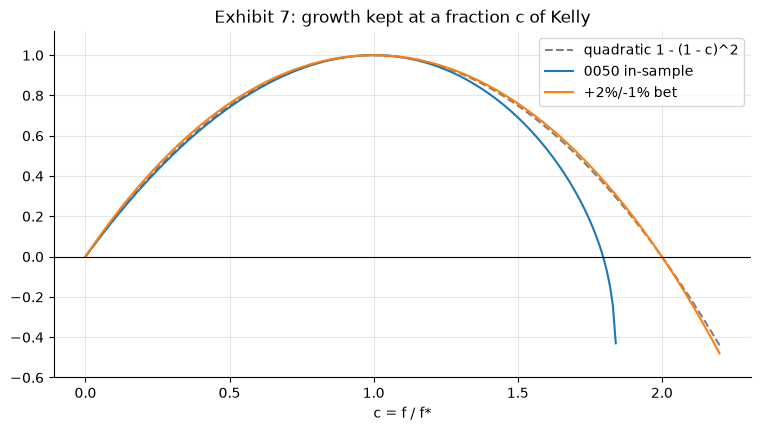

c,0050 exact,+2/-1 bet exact,quadratic
f64,f64,f64,f64
0.250000,0.429470,0.452056,0.437500
0.500000,0.741598,0.760824,0.750000
0.750000,0.933772,0.940835,0.937500
0.900000,0.989203,0.990561,0.990000
1.100000,0.988861,0.990561,0.990000
1.250000,0.928256,0.940835,0.937500
1.500000,0.691186,0.760824,0.750000
1.750000,0.179475,0.452056,0.437500


In [16]:
cs = [0.25, 0.5, 0.75, 0.9, 1.1, 1.25, 1.5, 1.75]
share = pl.DataFrame({"c": cs}).with_columns(
    pl.Series("0050 exact", [gbar(c * f_star) / g_star for c in cs]),
    pl.Series("+2/-1 bet exact", [g_bin(c * 25, 0.5, 0.02, 0.01) / g_star_bin(0.5, 0.02, 0.01) for c in cs]),
    (1 - (1 - pl.col("c")) ** 2).alias("quadratic"),
)
check(gbar(1.5 * f_star) / g_star, 0.691, 3, "0050 share at 1.5x Kelly")
check(gbar(1.75 * f_star) / g_star, 0.179, 3, "0050 share at 1.75x Kelly")
check(hi / f_star, 1.845, 3, "end of the 0050 curve, c = 10/f*")
c_grid = np.linspace(0, 2.2, 221)
fig, ax = plt.subplots()
ax.plot(c_grid, 1 - (1 - c_grid) ** 2, "--", color="grey", label="quadratic 1 - (1 - c)^2")
ok = c_grid * f_star < hi * (1 - 1e-9)
ax.plot(c_grid[ok], [gbar(c * f_star) / g_star for c in c_grid[ok]], label="0050 in-sample")
ax.plot(c_grid, [g_bin(c * 25, 0.5, 0.02, 0.01) / g_star_bin(0.5, 0.02, 0.01) for c in c_grid], label="+2%/-1% bet")
ax.set_ylim(-0.6, 1.12); ax.axhline(0, color="black", lw=0.8); ax.set_xlabel("c = f / f*")
ax.set_title("Exhibit 7: growth kept at a fraction c of Kelly"); ax.legend(); plt.show()
share   # Exhibit 7

In [17]:
# Example 6: half Kelly and the flat-top approximation (4.14)
pred = 0.5 * abs(d2g(f_star)) * A * (f_star / 2) ** 2
print(f"g''(f*) = {d2g(f_star):.4e} a day = {d2g(f_star) * A:.4f} a year;  predicted loss {pred:.1%}, actual {(g_star - gbar(f_star / 2)) * A:.1%}")

# Example 7: a simple rate r_f per trading day; envelope derivative 1 - f* at r_f = 0
print(f"mean of 1/(1 + f* R) = {(1 / (1 + f_star * R)).mean():.12f};  dV/dr_f = 1 - f* = {1 - f_star:.2f}")
rf_d = 0.02 / A                                              # 2% a year charged as 2%/A per trading day
f_r = brentq(lambda f: float(((R - rf_d) / (1 + rf_d + f * (R - rf_d))).mean()), 0, 9.99, xtol=1e-14)
V_r = float(np.log1p(rf_d + f_r * (R - rf_d)).mean()) * A
V_old = float(np.log1p(rf_d + f_star * (R - rf_d)).mean()) * A
print(f"2% a year ({rf_d:.4%} per trading day): first-order {(1 - f_star) * 0.02:.2%}, exact {V_r - g_star * A:.2%};  "
      f"f*(r_f) = {f_r:.2f}, V = {V_r:.2%}, old f* earns {V_old:.2%}")
check(V_r - g_star * A, -0.0838, 4, "exact fall in maximal growth at 2% financing")

g''(f*) = -1.8041e-04 a day = -0.0439 a year;  predicted loss 16.1%, actual 15.2%
mean of 1/(1 + f* R) = 1.000000000000;  dV/dr_f = 1 - f* = -4.42
2% a year (0.0082% per trading day): first-order -8.84%, exact -8.38%;  f*(r_f) = 4.96, V = 50.46%, old f* earns 49.99%
ok  exact fall in maximal growth at 2% financing: -0.083793 (module: -0.0838)


In [18]:
# Example 8: sampling error of the mean and the implied band of Kelly leverages (preview of LM20 and LM45).
# Every daily return is shifted by the same amount so that the sample mean sits at either end of the 95% interval,
# and the EXACT Kelly condition is solved on the shifted sample.
se = math.sqrt(s2) / math.sqrt(T)
lo_mu, hi_mu = mu - 1.96 * se, mu + 1.96 * se
print(f"SE(mu) = {se:.4%} a day, t = {mu / se:.2f}, relative error {se / mu:.1%};  95% interval [{lo_mu:.3%}, {hi_mu:.3%}]")
band = {}
for side, shift in (("lower", -1.96 * se), ("upper", 1.96 * se)):
    Rs = R + shift
    f_end = kelly(Rs)
    c = f_star / f_end
    band[side] = (f_end, c, 1 - (1 - c) ** 2, gbar(f_star, Rs) * A, gbar(f_star, Rs) / gbar(f_end, Rs))
    print(f"{side} end: exact f* = {f_end:.4f} (rule mu/s^2 {Rs.mean() / Rs.var():.2f}); holding {f_star:.2f} is c = {c:.3f}: "
          f"quadratic share {1 - (1 - c) ** 2:.1%}; on the shifted sample it earns {gbar(f_star, Rs) * A:.2%} a year "
          f"({gbar(f_star, Rs) / gbar(f_end, Rs):.1%} of the maximum)")
check(se / mu, 0.26, 2, "relative error of the mean")
check(band["lower"][0], 2.7, 1, "lower end of the band"); check(band["upper"][0], 7.6, 1, "upper end of the band")
check((mu - 1.96 * se) / s2, 2.7, 1, "rule mu/s^2 at the lower end"); check((mu + 1.96 * se) / s2, 8.6, 1, "rule mu/s^2 at the upper end")
check(band["lower"][1], 2.0, 1, "c at the lower end")
check(band["lower"][2], 0.0, 1, "quadratic share at the lower end: almost nothing")
check(1 - (1 - 5.42 / 2.7) ** 2, 0.0, 1, "the same from the printed 5.42 and 2.7")
check(band["lower"][3], -0.0063, 4, "growth of f* on the down-shifted sample")
check(band["upper"][1], 0.71, 2, "c at the upper end"); check(band["upper"][2], 0.92, 2, "quadratic share at the upper end")
check(band["upper"][4], 0.90, 2, "exact share on the up-shifted sample")

SE(mu) = 0.0230% a day, t = 3.79, relative error 26.4%;  95% interval [0.042%, 0.132%]
lower end: exact f* = 2.7161 (rule mu/s^2 2.74); holding 5.42 is c = 1.996: quadratic share 0.8%; on the shifted sample it earns -0.63% a year (-4.5% of the maximum)
upper end: exact f* = 7.6163 (rule mu/s^2 8.62); holding 5.42 is c = 0.712: quadratic share 91.7%; on the shifted sample it earns 118.16% a year (90.3% of the maximum)
ok  relative error of the mean: 0.2639 (module: 0.26)
ok  lower end of the band: 2.716 (module: 2.7)
ok  upper end of the band: 7.616 (module: 7.6)
ok  rule mu/s^2 at the lower end: 2.742 (module: 2.7)
ok  rule mu/s^2 at the upper end: 8.617 (module: 8.6)
ok  c at the lower end: 1.996 (module: 2.0)
ok  quadratic share at the lower end: almost nothing: 0.008 (module: 0.0)
ok  the same from the printed 5.42 and 2.7: -0.015 (module: 0.0)
ok  growth of f* on the down-shifted sample: -0.006288 (module: -0.0063)
ok  c at the upper end: 0.7118 (module: 0.71)
ok  quadratic share a

shape: (1, 3)
┌──────────┬──────────┬──────────┐
│ min      ┆ max      ┆ last     │
│ ---      ┆ ---      ┆ ---      │
│ f64      ┆ f64      ┆ f64      │
╞══════════╪══════════╪══════════╡
│ 0.941754 ┆ 8.871458 ┆ 6.632173 │
└──────────┴──────────┴──────────┘


lowest window ends 2024-01-17 ; highest window ends 2018-08-13


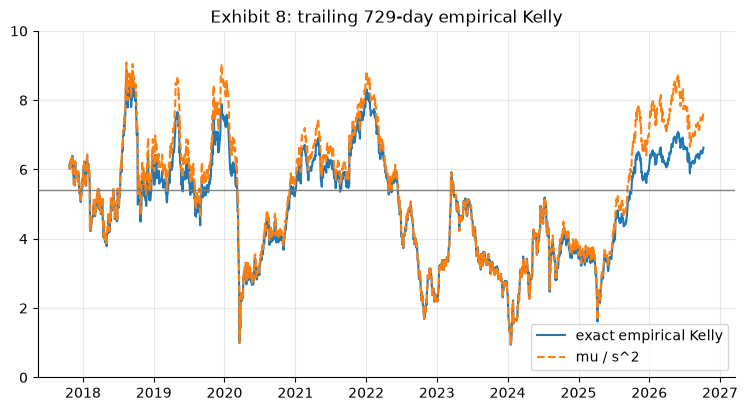

ok  rolling minimum: 0.9418 (module: 0.94)
ok  rolling maximum: 8.8715 (module: 8.87)


In [19]:
# Exhibit 8: rolling three-year (729-day) empirical Kelly
W = 729
roll = pl.DataFrame({"end": ret["date"][W - 1:],
                     "f*": [kelly(R[e - W:e], xtol=1e-10) for e in range(W, T + 1)],
                     "mu/s2": [R[e - W:e].mean() / R[e - W:e].var() for e in range(W, T + 1)]})
print(roll.select(pl.col("f*").min().alias("min"), pl.col("f*").max().alias("max"), pl.col("f*").last().alias("last")))
print("lowest window ends", roll["end"][int(roll["f*"].arg_min())], "; highest window ends", roll["end"][int(roll["f*"].arg_max())])
fig, ax = plt.subplots()
ax.plot(roll["end"], roll["f*"], label="exact empirical Kelly"); ax.plot(roll["end"], roll["mu/s2"], "--", label="mu / s^2")
ax.axhline(f_star, color="grey", lw=1); ax.set_ylim(0, 10); ax.set_title("Exhibit 8: trailing 729-day empirical Kelly"); ax.legend(); plt.show()
check(roll["f*"].min(), 0.94, 2, "rolling minimum"); check(roll["f*"].max(), 8.87, 2, "rolling maximum")

In [20]:
# Pitfall: "backtest Sharpe 3 -> full Kelly"  (quadratic model, annualized SR and sigma)
SR_bt, sigma = 3.0, 0.15
f_bt = SR_bt / sigma
for SR_true in (1.5, 1.0):
    c = SR_bt / SR_true
    g = (2 * c - c**2) * SR_true**2 / 2
    print(f"true SR {SR_true}: leverage {f_bt:.0f} is c = {c:.0f} times Kelly; growth {g:+.2f} a year, wealth factor {math.exp(g):.3f}")
print(f"0050 in-sample: SR = {mu * A / math.sqrt(s2 * A):.2f}, SR/sigma = {mu * A / (s2 * A):.2f}, SR^2/2 = {(mu * A) ** 2 / (s2 * A) / 2:.1%}")

true SR 1.5: leverage 20 is c = 2 times Kelly; growth +0.00 a year, wealth factor 1.000
true SR 1.0: leverage 20 is c = 3 times Kelly; growth -1.50 a year, wealth factor 0.223
0050 in-sample: SR = 1.10, SR/sigma = 5.68, SR^2/2 = 60.1%


## Part 7 — `scipy.optimize` (Section 8)

In [21]:
# Section 8 of the module builds R from the same data/ files in a few lines; it gives exactly the returns of Part 1
common = pl.read_csv("data/00631L_daily_raw.csv").select("date")
div_s8 = pl.read_csv("data/0050_dividends.csv")
px = (pl.read_csv("data/0050_daily_raw.csv").join(common, on="date")
        .join(div_s8, on="date", how="left").sort("date"))
split = pl.when(pl.col("date") == pl.lit("2025-06-18")).then(4.0).otherwise(1.0)
P, D = pl.col("close"), pl.col("cash_dividend").fill_null(0.0)
R_s8 = (px.select((P + D) * split / P.shift(1) - 1)
          .to_series().drop_nulls().to_numpy())
assert np.array_equal(R_s8, R)

f_b = brentq(dg, 0.0, 0.999 * hi, xtol=1e-14)
f_n = newton(dg, x0=0.0, fprime=d2g, tol=1e-14)
f_m = minimize_scalar(lambda f: -gbar(f), bounds=(0.0, 0.999 * hi), method="bounded").x
line = f"domain ({lo:.2f}, {hi:.2f})  brentq {f_b:.6f}  newton {f_n:.6f}  bounded {f_m:.4f}"
print(line)
assert line == "domain (-10.00, 10.00)  brentq 5.421488  newton 5.421488  bounded 5.4215"   # the module's output line

import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore")                       # log1p of negative numbers outside the domain
    res = minimize_scalar(lambda f: -gbar(f))             # unbounded Brent search: leaves (-10, 10)
print("unbounded search:", res.x, "|", getattr(res, "message", ""))

domain (-10.00, 10.00)  brentq 5.421488  newton 5.421488  bounded 5.4215
unbounded search: nan | The algorithm terminated without finding a valid bracket. Consider trying different initial points.


## Part 8 — Practice-problem solutions (computational) and an extension

In [22]:
print("PP3 ", f"f*={0.12 / 0.16:.2f}  g*={0.12**2 / 0.32:.4f}  half={0.12 * 0.375 - 0.08 * 0.375**2:.5f}  zero={0.12 / 0.08:.2f}")
print("PP4 ", f"f*={f_bin(0.55, 0.05, 0.05):.2f}")
f6, f6b = f_bin(0.30, 0.08, 0.02), f_bin(0.25, 0.08, 0.02)
print("PP6 ", f"f*={f6:.3f} risk={f6 * 0.02:.1%} g*={g_star_bin(0.30, 0.08, 0.02):.3%}  true p=0.25: f*={f6b:.3f} ratio={f6 / f6b:.2f} "
      f"growth={g_bin(f6, 0.25, 0.08, 0.02):.3%} vs {g_star_bin(0.25, 0.08, 0.02):.3%}")
print("PP7 ", f"log2(1e8) = {math.log2(1e8):.2f} -> {math.ceil(math.log2(1e8))} steps (natural log would give {math.ceil(math.log(1e8))})")
g8 = lambda f: 0.10 * f - 0.05 * f**2
print("PP8 ", f"corner 0.8: g={g8(0.8):.3f}  shadow price={0.10 - 0.10 * 0.8:.3f};  limit 0.9 adds {g8(0.9) - g8(0.8):.4f} "
      f"(first-order {0.02 * 0.1:.4f});  the whole gain to f*=1 is {g8(1.0) - g8(0.8):.4f}")
c = 2.4 / 0.8
print("PP11", f"f={2.4 / 0.12:.0f}  zero-growth SR={2.4 / 2}  growth at SR 0.8: {(2 * c - c**2) * 0.8**2 / 2:.2f} (x{math.exp((2 * c - c**2) * 0.8**2 / 2):.3f})")
r20 = ret.filter(pl.col("date") >= pl.lit("2020-01-01").str.to_date())["R"].to_numpy()
print("PP12", f"n={len(r20)}  f*={kelly(r20):.2f}  mu/s2={r20.mean() / r20.var():.2f}")
p, b, a = 0.5, 0.02, 0.01
mu_b = p * b - (1 - p) * a; s_b = math.sqrt(p * b * b + (1 - p) * a * a - mu_b**2)
print("PP13", f"(pb-qa)/(pb^2+qa^2) = {(p * b - (1 - p) * a) / (p * b**2 + (1 - p) * a**2):.1f};  "
      f"pb^3-qa^3 = {p * b**3 - (1 - p) * a**3:.2e} = mu^3+3 mu sigma^2 = {mu_b**3 + 3 * mu_b * s_b**2:.2e}")
check(g8(0.9) - g8(0.8), 0.0015, 4, "PP8: gain from a 0.9 limit")
check(kelly(r20), 5.38, 2, "PP12: 2020-2026 Kelly leverage"); check(r20.mean() / r20.var(), 5.66, 2, "PP12: mu/s^2")
check(r20.mean() / r20.var() / kelly(r20) - 1, 0.05, 2, "PP12: mu/s^2 too high, window")
check(mu / s2 / f_star - 1, 0.05, 2, "PP12: mu/s^2 too high, full sample")

# PP6(b): growth kept at twice Kelly, and where growth really returns to zero. A rare large gain (p < 0.5) makes growth
# fall more slowly beyond f* than it rises below it, so g(2f*) > g(0) = 0; at p = 0.5 the curve is symmetric about f*.
share6 = g_bin(f6, 0.25, 0.08, 0.02) / g_star_bin(0.25, 0.08, 0.02)
z6 = brentq(lambda f: g_bin(f, 0.25, 0.08, 0.02), f6b, 50 * (1 - 1e-12))
print("PP6(b)", f"share kept {share6:.1%};  exact zero growth at {z6:.2f} = {z6 / f6b:.2f} x Kelly")
check(share6, 0.165, 3, "PP6(b): share of the attainable growth kept")
check(z6, 6.56, 2, "PP6(b): exact zero-growth position"); check(z6 / f6b, 2.10, 2, "PP6(b): the same in multiples of Kelly")
dist = np.linspace(0.01, 1.0, 100)                  # distances from the optimum, as fractions of f*
gap6 = [g_bin(f6b * (1 + x), 0.25, 0.08, 0.02) - g_bin(f6b * (1 - x), 0.25, 0.08, 0.02) for x in dist]
gap_half = [g_bin(25 * (1 + x), 0.5, 0.02, 0.01) - g_bin(25 * (1 - x), 0.5, 0.02, 0.01) for x in dist]
print(f"g(f* + d) - g(f* - d), 0 < d <= f*:  p = 0.25 (rare large gain) smallest {min(gap6):.2e};  "
      f"+2/-1 bet at p = 0.5 largest |.| {max(map(abs, gap_half)):.1e}")
assert min(gap6) > 0 and max(map(abs, gap_half)) < 1e-15
# the cubic term does not decide it: it is positive for the +2/-1 bet at p = 0.5, whose zero is exactly at 2f* = 50
print(f"+2/-1 bet at p = 0.5: g(50) = {g_bin(50, 0.5, 0.02, 0.01):.1e}, although pb^3 - qa^3 = {0.5 * 0.02**3 - 0.5 * 0.01**3:.1e} > 0")

# PP13: a positive mean does not fix the sign of the cubic term (+1% with probability 0.9 against -5%)
p, b, a = 0.9, 0.01, 0.05
rule = (p * b - (1 - p) * a) / (p * b**2 + (1 - p) * a**2)
print("PP13 counterexample", f"pb - qa = {p * b - (1 - p) * a:+.2%}, pb^3 - qa^3 = {p * b**3 - (1 - p) * a**3:.2e}, "
      f"quadratic rule {rule:.1f} against an exact {f_bin(p, b, a):.0f}")
assert p * b**3 - (1 - p) * a**3 < 0
check(rule, 11.8, 1, "PP13: quadratic rule for the counterexample"); check(f_bin(p, b, a), 8, 0, "PP13: exact Kelly position")

PP3  f*=0.75  g*=0.0450  half=0.03375  zero=1.50
PP4  f*=2.00
PP6  f*=6.250 risk=12.5% g*=2.817%  true p=0.25: f*=3.125 ratio=2.00 growth=0.122% vs 0.738%
PP7  log2(1e8) = 26.58 -> 27 steps (natural log would give 19)
PP8  corner 0.8: g=0.048  shadow price=0.020;  limit 0.9 adds 0.0015 (first-order 0.0020);  the whole gain to f*=1 is 0.0020
PP11 f=20  zero-growth SR=1.2  growth at SR 0.8: -0.96 (x0.383)
PP12 n=1635  f*=5.38  mu/s2=5.66
PP13 (pb-qa)/(pb^2+qa^2) = 20.0;  pb^3-qa^3 = 3.50e-06 = mu^3+3 mu sigma^2 = 3.50e-06
ok  PP8: gain from a 0.9 limit: 0.001500 (module: 0.0015)
ok  PP12: 2020-2026 Kelly leverage: 5.3819 (module: 5.38)
ok  PP12: mu/s^2: 5.6573 (module: 5.66)
ok  PP12: mu/s^2 too high, window: 0.0512 (module: 0.05)
ok  PP12: mu/s^2 too high, full sample: 0.0476 (module: 0.05)
PP6(b) share kept 16.5%;  exact zero growth at 6.56 = 2.10 x Kelly
ok  PP6(b): share of the attainable growth kept: 0.16496 (module: 0.165)
ok  PP6(b): exact zero-growth position: 6.5562 (module: 6.5

### Extension: walk-forward Kelly

The module's warning is that an in-sample optimum is not a recommendation. Test it. At each month-end from November 2017, estimate $f^*$ on the trailing 729 days, cap it to $[0,3]$, and hold that leverage for the next month. Compare the realized log growth with constant $f=1$ and with a constant half of the full-sample $f^*$ (which uses future data and is therefore not a fair benchmark either). The scaffold below builds the month-end schedule and the walk-forward leverage; complete the comparison and explain the result with Sections 4 and 7. LM22 (resampling) and LM45 (Kelly under uncertainty) return to this question.

In [23]:
month_end = (ret.with_row_index("i")
                .group_by_dynamic("date", every="1mo").agg(pl.col("i").last())
                .filter(pl.col("i") >= W - 1))
lev = np.full(T, np.nan)
ends = month_end["i"].to_list()
for k, e in enumerate(ends):
    f_hat = min(max(kelly(R[e - W + 1:e + 1], xtol=1e-10), 0.0), 3.0)
    nxt = ends[k + 1] if k + 1 < len(ends) else T - 1
    lev[e + 1:nxt + 1] = f_hat
mask = ~np.isnan(lev)
print(f"walk-forward days: {mask.sum()};  average leverage {np.nanmean(lev):.2f}")
# TODO: compute annual log growth of the walk-forward rule, of f = 1 and of f = f_star / 2 over the same days,
#       e.g. np.log1p(lev[mask] * R[mask]).sum() / (mask.sum() / A), and compare their maximum drawdowns.

walk-forward days: 2167;  average leverage 2.95
